In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%matplotlib inline
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold, cross_val_score, cross_val_predict
from sklearn import metrics

from sklearn import svm
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

In [ ]:
df = pd.read_excel('/content/drive/MyDrive/Colab Notebooks/train.xlsx')
df

,GRID_ID,month,day,hol,pop,평균 풍속(m/s),b_point,a_point,n_point,cat
0,378509,1,1,1,5.22,1.8,37,0,0,NaN
1,378509,1,2,1,0.00,1.9,37,0,0,NaN
2,378509,1,3,1,0.00,1.2,37,0,0,NaN
3,378509,1,4,0,0.00,1.3,37,0,0,NaN
4,378509,1,5,0,0.00,1.8,37,0,0,NaN
...,...,...,...,...,...,...,...,...,...,...
167670,418518,12,26,1,0.00,0.8,17,0,0,NaN
167671,418518,12,27,0,0.00,0.8,17,0,0,NaN
167672,418518,12,28,0,0.00,0.5,17,0,0,NaN
167673,418518,12,29,0,0.00,0.8,17,0,0,NaN


In [ ]:
df = df[df['month']!=12]
df

,GRID_ID,month,day,hol,pop,평균 풍속(m/s),b_point,a_point,n_point,cat
0,378509,1,1,1,5.22,1.8,37,0,0,NaN
1,378509,1,2,1,0.00,1.9,37,0,0,NaN
2,378509,1,3,1,0.00,1.2,37,0,0,NaN
3,378509,1,4,0,0.00,1.3,37,0,0,NaN
4,378509,1,5,0,0.00,1.8,37,0,0,NaN
...,...,...,...,...,...,...,...,...,...,...
167640,418518,11,25,0,0.00,1.6,17,0,0,NaN
167641,418518,11,26,0,0.00,1.6,17,0,0,NaN
167642,418518,11,27,1,0.00,1.1,17,0,0,NaN
167643,418518,11,28,1,0.00,1.3,17,0,0,NaN


In [ ]:
df.isnull().sum()

GRID_ID            0
month              0
day                0
hol                0
pop                0
평균 풍속(m/s)         0
b_point            0
a_point            0
n_point            0
cat           150815
dtype: int64

In [ ]:
df=df.fillna('n')
df

,GRID_ID,month,day,hol,pop,평균 풍속(m/s),b_point,a_point,n_point,cat
0,378509,1,1,1,5.22,1.8,37,0,0,n
1,378509,1,2,1,0.00,1.9,37,0,0,n
2,378509,1,3,1,0.00,1.2,37,0,0,n
3,378509,1,4,0,0.00,1.3,37,0,0,n
4,378509,1,5,0,0.00,1.8,37,0,0,n
...,...,...,...,...,...,...,...,...,...,...
167640,418518,11,25,0,0.00,1.6,17,0,0,n
167641,418518,11,26,0,0.00,1.6,17,0,0,n
167642,418518,11,27,1,0.00,1.1,17,0,0,n
167643,418518,11,28,1,0.00,1.3,17,0,0,n


In [ ]:
# 행별 고유 인덱스 부여
df2 = df.copy()
df2['index'] = df2[['GRID_ID', 'month', 'day']].apply(lambda row: ','.join(row.values.astype(str)), axis=1)
df2.set_index('index', inplace=True)
df2 = df2.drop(columns=['GRID_ID'])

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
cols = list(df2.columns)
cols.remove('cat')
# cols
for col in cols:
    df2[col] = scaler.fit_transform(df2[[col]])
df2

,month,day,hol,pop,평균 풍속(m/s),b_point,a_point,n_point,cat
index,,,,,,,,,
"378509,1,1",-1.590986,-1.671225,1.482572,-0.297122,-0.269646,-0.170462,-0.181883,-0.483462,n
"378509,1,2",-1.590986,-1.553492,1.482572,-0.297434,-0.202665,-0.170462,-0.181883,-0.483462,n
"378509,1,3",-1.590986,-1.435759,1.482572,-0.297434,-0.671531,-0.170462,-0.181883,-0.483462,n
"378509,1,4",-1.590986,-1.318026,-0.674503,-0.297434,-0.604550,-0.170462,-0.181883,-0.483462,n
"378509,1,5",-1.590986,-1.200293,-0.674503,-0.297434,-0.269646,-0.170462,-0.181883,-0.483462,n
...,...,...,...,...,...,...,...,...,...
"418518,11,25",1.579208,1.154366,-0.674503,-0.297434,-0.403608,-0.279454,-0.181883,-0.483462,n
"418518,11,26",1.579208,1.272099,-0.674503,-0.297434,-0.403608,-0.279454,-0.181883,-0.483462,n
"418518,11,27",1.579208,1.389832,1.482572,-0.297434,-0.738512,-0.279454,-0.181883,-0.483462,n


In [ ]:
x_train = df2.iloc[:, :-1]
y_train = df2.iloc[:, -1]

In [ ]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
encoder= encoder.fit(y_train) 
y_train = encoder.transform(y_train) 

In [ ]:
# 데이터 분리
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x_train, y_train, shuffle=True, stratify=None,random_state=1004,test_size=0.2)

In [ ]:
import numpy as np

def CreateBalancedSampleWeights(y_train, largest_class_weight_coef):
    classes = np.unique(y_train, axis = 0)
    classes.sort()
    class_samples = np.bincount(y_train)
    total_samples = class_samples.sum()
    n_classes = len(class_samples)
    weights = total_samples / (n_classes * class_samples * 1.0)
    class_weight_dict = {key : value for (key, value) in zip(classes, weights)}
    class_weight_dict[classes[1]] = class_weight_dict[classes[1]] * largest_class_weight_coef
    sample_weights = [class_weight_dict[y] for y in y_train]

    return sample_weights

In [ ]:
largest_class_weight_coef = max(df2['cat'].value_counts().values)/df2.shape[0]
weights = CreateBalancedSampleWeights(y_train, largest_class_weight_coef)

# RandomForestClassifier

In [ ]:
model = RandomForestClassifier(n_estimators=100)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print('RandomForestClassifier: %.2f' % (metrics.accuracy_score(y_pred, y_test) * 100))

RandomForestClassifier: 98.28


In [ ]:
y_pred

array([26, 26, 26, ..., 26, 26, 26])

In [ ]:
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
print('정확도: {0:.4f}'.format(accuracy_score(y_test, y_pred)))

정확도: 0.9828


In [ ]:
#model.save('RandomForestClassifier.h5')  # 위의 모델 저장

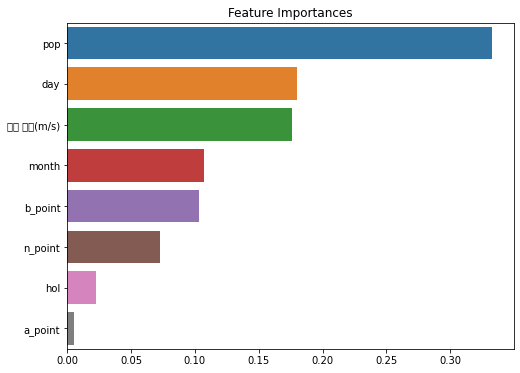

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm
plt.rc('font', family='NanumGothic')
%matplotlib inline

ftr_importances_values = model.feature_importances_
ftr_importances = pd.Series(ftr_importances_values, index=X_train.columns)
ftr_importances = ftr_importances.sort_values(ascending=False)

plt.figure(figsize=(8, 6))
plt.title('Feature Importances')
sns.barplot(x=ftr_importances, y=ftr_importances.index)

In [ ]:
df2.reset_index(drop=False, inplace=True)

In [ ]:
X_test.reset_index(drop=False, inplace=True)

In [ ]:
df_ch = pd.merge(df2, X_test, how='inner')
df_ch

,index,month,day,hol,pop,평균 풍속(m/s),b_point,a_point,n_point,cat
0,"378509,1,3",-1.590986,-1.435759,1.482572,-0.297434,-0.671531,-0.170462,-0.181883,-0.483462,n
1,"378509,1,5",-1.590986,-1.200293,-0.674503,-0.297434,-0.269646,-0.170462,-0.181883,-0.483462,n
2,"378509,1,7",-1.590986,-0.964827,-0.674503,-0.297434,0.601106,-0.170462,-0.181883,-0.483462,n
3,"378509,1,11",-1.590986,-0.493895,-0.674503,-0.297434,-0.403608,-0.170462,-0.181883,-0.483462,n
4,"378509,1,12",-1.590986,-0.376162,-0.674503,-0.297434,-0.202665,-0.170462,-0.181883,-0.483462,n
...,...,...,...,...,...,...,...,...,...,...
30680,"418518,11,9",1.579208,-0.729361,-0.674503,-0.297434,-0.738512,-0.279454,-0.181883,-0.483462,n
30681,"418518,11,11",1.579208,-0.493895,-0.674503,-0.297434,-0.001722,-0.279454,-0.181883,-0.483462,n
30682,"418518,11,20",1.579208,0.565701,1.482572,-0.297434,-0.805493,-0.279454,-0.181883,-0.483462,n
30683,"418518,11,24",1.579208,1.036633,-0.674503,-0.297434,0.132240,-0.279454,-0.181883,-0.483462,n


In [ ]:
pred = pd.DataFrame(y_pred, columns=['pred'])

In [ ]:
ch = pd.concat([X_test, pred], axis=1)

In [ ]:
for i, label in enumerate(encoder.classes_):
  print(i, "->", label) 

0 -> ACDNT_INJ_OCRN_CNT
1 -> ANML_INSCT_ACDNT_OCRN_CNT
2 -> ASPHYXIA_OCRN_CNT
3 -> BCYC_ACDNT_OCRN_CNT
4 -> BLTRM_OCRN_CNT
5 -> BURN_OCRN_CNT
6 -> DRKNSTAT_OCRN_CNT
7 -> DRV_ACDNT_OCRN_CNT
8 -> DRWNG_OCRN_CNT
9 -> ELTRC_ACDNT_OCRN_CNT
10 -> ETC_OCRN_CNT
11 -> EXCL_DISEASE_OCRN_CNT
12 -> FALLING_OCRN_CNT
13 -> FLAME_OCRN_CNT
14 -> FLPS_ACDNT_OCRN_CNT
15 -> HGTPOJ_ACDNT_OCRN_CNT
16 -> HRFAF_OCRN_CNT
17 -> LACRTWND_OCRN_CNT
18 -> MCHN_ACDNT_OCRN_CNT
19 -> MTRCYC_ACDNT_OCRN_CNT
20 -> PDST_ACDNT_OCRN_CNT
21 -> POSNG_OCRN_CNT
22 -> PRGNTW_ACDNT_OCRN_CNT
23 -> THML_DAMG_OCRN_CNT
24 -> UNKNWN_OCRN_CNT
25 -> VHC_ACDNT_OCRN_CNT
26 -> n


In [ ]:
ch.to_excel("RFC.xlsx", index=False)

In [ ]:
ch= pd.read_excel('/content/RFC.xlsx')
ch

,index,month,day,hol,pop,평균 풍속(m/s),b_point,a_point,n_point,pred
0,"385526,5,25",-0.322908,1.154366,-0.674503,-0.275756,-0.001722,-0.306701,-0.181883,-0.483462,26
1,"391530,11,14",1.579208,-0.140696,1.482572,-0.297374,-0.537570,-0.361197,-0.181883,-0.483462,26
2,"381530,3,11",-0.956947,-0.493895,-0.674503,-0.297434,-1.006436,-0.274004,-0.181883,-0.483462,26
3,"392523,5,18",-0.322908,0.330235,-0.674503,-0.065194,0.132240,0.042071,-0.181883,0.306712,26
4,"380521,3,23",-0.956947,0.918900,-0.674503,-0.297434,0.199220,-0.355747,-0.181883,-0.483462,26
...,...,...,...,...,...,...,...,...,...,...
30680,"399534,1,28",-1.590986,1.507565,-0.674503,-0.296441,0.199220,-0.154114,-0.181883,-0.483462,26
30681,"390520,4,29",-0.639928,1.625298,-0.674503,-0.297434,0.132240,-0.366647,-0.181883,-0.483462,26
30682,"380527,9,28",0.945169,1.507565,-0.674503,-0.297434,-0.403608,-0.372096,-0.181883,-0.483462,26
30683,"396527,10,28",1.262189,1.507565,-0.674503,1.692412,0.668087,5.420788,4.900148,2.677233,26


In [ ]:
ch['pred'].value_counts()

26    30665
16       10
21        3
11        2
4         1
20        1
10        1
6         1
3         1
Name: pred, dtype: int64

In [ ]:
df_ch.to_excel("df_RFC.xlsx", index=False)

In [ ]:
df_RFC= pd.read_excel('/content/df_RFC.xlsx')
df_RFC

,index,month,day,hol,pop,평균 풍속(m/s),b_point,a_point,n_point,cat
0,"378509,1,3",-1.590986,-1.435759,1.482572,-0.297434,-0.671531,-0.170462,-0.181883,-0.483462,n
1,"378509,1,5",-1.590986,-1.200293,-0.674503,-0.297434,-0.269646,-0.170462,-0.181883,-0.483462,n
2,"378509,1,7",-1.590986,-0.964827,-0.674503,-0.297434,0.601106,-0.170462,-0.181883,-0.483462,n
3,"378509,1,11",-1.590986,-0.493895,-0.674503,-0.297434,-0.403608,-0.170462,-0.181883,-0.483462,n
4,"378509,1,12",-1.590986,-0.376162,-0.674503,-0.297434,-0.202665,-0.170462,-0.181883,-0.483462,n
...,...,...,...,...,...,...,...,...,...,...
30680,"418518,11,9",1.579208,-0.729361,-0.674503,-0.297434,-0.738512,-0.279454,-0.181883,-0.483462,n
30681,"418518,11,11",1.579208,-0.493895,-0.674503,-0.297434,-0.001722,-0.279454,-0.181883,-0.483462,n
30682,"418518,11,20",1.579208,0.565701,1.482572,-0.297434,-0.805493,-0.279454,-0.181883,-0.483462,n
30683,"418518,11,24",1.579208,1.036633,-0.674503,-0.297434,0.132240,-0.279454,-0.181883,-0.483462,n


In [ ]:
df_RFC['cat'].value_counts()

n                            30170
HRFAF_OCRN_CNT                 198
DRV_ACDNT_OCRN_CNT              45
EXCL_DISEASE_OCRN_CNT           44
MTRCYC_ACDNT_OCRN_CNT           38
ACDNT_INJ_OCRN_CNT              26
PDST_ACDNT_OCRN_CNT             23
FLPS_ACDNT_OCRN_CNT             23
LACRTWND_OCRN_CNT               22
BCYC_ACDNT_OCRN_CNT             15
FALLING_OCRN_CNT                15
DRKNSTAT_OCRN_CNT               13
ETC_OCRN_CNT                    13
POSNG_OCRN_CNT                   9
BLTRM_OCRN_CNT                   9
ANML_INSCT_ACDNT_OCRN_CNT        9
VHC_ACDNT_OCRN_CNT               3
MCHN_ACDNT_OCRN_CNT              3
THML_DAMG_OCRN_CNT               2
UNKNWN_OCRN_CNT                  2
ASPHYXIA_OCRN_CNT                1
DRWNG_OCRN_CNT                   1
FLAME_OCRN_CNT                   1
Name: cat, dtype: int64

# test 데이터로 예측하기

In [ ]:
test_df = pd.read_excel('/content/drive/MyDrive/Colab Notebooks/test.xlsx')
test_df

,GRID_ID,month,day,hol,pop,평균 풍속(m/s),b_point,a_point,n_point
0,378509,1,31,1,0.500000,2.3,37,0,0
1,379506,1,31,1,0.000000,2.3,6,0,0
2,379507,1,31,1,0.632333,2.3,48,0,0
3,380508,1,31,1,0.000000,2.3,27,0,5
4,378511,1,31,1,13.796333,2.3,82,0,11
...,...,...,...,...,...,...,...,...,...
5695,417521,11,30,0,0.000000,2.3,57,0,1
5696,418518,11,30,0,0.000000,2.3,17,0,0
5697,417518,12,31,0,0.000000,1.6,41,0,0
5698,417521,12,31,0,0.000000,1.6,57,0,1


In [ ]:
test = test_df.iloc[:, :]
test

,GRID_ID,month,day,hol,pop,평균 풍속(m/s),b_point,a_point,n_point
0,378509,1,31,1,0.500000,2.3,37,0,0
1,379506,1,31,1,0.000000,2.3,6,0,0
2,379507,1,31,1,0.632333,2.3,48,0,0
3,380508,1,31,1,0.000000,2.3,27,0,5
4,378511,1,31,1,13.796333,2.3,82,0,11
...,...,...,...,...,...,...,...,...,...
5695,417521,11,30,0,0.000000,2.3,57,0,1
5696,418518,11,30,0,0.000000,2.3,17,0,0
5697,417518,12,31,0,0.000000,1.6,41,0,0
5698,417521,12,31,0,0.000000,1.6,57,0,1


In [ ]:
test1 = test.copy()
test1['index'] = test1[['GRID_ID', 'month', 'day']].apply(lambda row: ','.join(row.values.astype(str)), axis=1)
test1.set_index('index', inplace=True)
test1 = test1.drop(columns=['GRID_ID'])
test1

,month,day,hol,pop,평균 풍속(m/s),b_point,a_point,n_point
index,,,,,,,,
"378509,1,31",1,31,1,0.500000,2.3,37,0,0
"379506,1,31",1,31,1,0.000000,2.3,6,0,0
"379507,1,31",1,31,1,0.632333,2.3,48,0,0
"380508,1,31",1,31,1,0.000000,2.3,27,0,5
"378511,1,31",1,31,1,13.796333,2.3,82,0,11
...,...,...,...,...,...,...,...,...
"417521,11,30",11,30,0,0.000000,2.3,57,0,1
"418518,11,30",11,30,0,0.000000,2.3,17,0,0
"417518,12,31",12,31,0,0.000000,1.6,41,0,0


In [ ]:
test_pred = model.predict(test1)
test_pred

array([26, 26, 26, ..., 26, 26, 26])

In [ ]:
#test1.reset_index(drop=False, inplace=True)

In [ ]:
#test1.reset_index(drop=False, inplace=True)

In [ ]:
#test_ch = pd.merge(test1, test1, how='inner')
#test_ch

In [ ]:
pred_t = pd.DataFrame(test_pred, columns=['pred'])

In [ ]:
ch_t = pd.concat([test1, pred_t], axis=1)

In [ ]:
ch_t_9 = pd.concat([test, pred_t], axis=1)

In [ ]:
ch_t.to_excel("RFC_test1.xlsx", index=False)

In [ ]:
ch_t_9.to_excel("RFC_test_grid.xlsx", index=False)

In [ ]:
#test_ch.to_excel("test_RFC.xlsx", index=False)

In [ ]:
RFC_test_grid= pd.read_excel('/content/RFC_test_grid.xlsx')
RFC_test_grid

,GRID_ID,month,day,hol,pop,평균 풍속(m/s),b_point,a_point,n_point,pred
0,378509,1,31,1,0.500000,2.3,37,0,0,26
1,379506,1,31,1,0.000000,2.3,6,0,0,26
2,379507,1,31,1,0.632333,2.3,48,0,0,26
3,380508,1,31,1,0.000000,2.3,27,0,5,26
4,378511,1,31,1,13.796333,2.3,82,0,11,26
...,...,...,...,...,...,...,...,...,...,...
5695,417521,11,30,0,0.000000,2.3,57,0,1,26
5696,418518,11,30,0,0.000000,2.3,17,0,0,26
5697,417518,12,31,0,0.000000,1.6,41,0,0,26
5698,417521,12,31,0,0.000000,1.6,57,0,1,26


In [ ]:
RFC_test_grid['pred'].value_counts()

26    5700
Name: pred, dtype: int64